# Experiment 2 — Data Preprocessing (Titanic Dataset)

**Covers:** Missing values, label encoding, one-hot encoding, standardization, Min-Max scaling, box plot, IQR table, outlier removal and CSV export.

**Dataset:** **Titanic** – `train.csv` from the Kaggle Titanic competition ([kaggle.com/c/titanic](https://www.kaggle.com/competitions/titanic/data)), 891 passengers, columns `PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked`.

**Data file:** keep `train.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\train.csv")`).

**Remember:** Missing → Encoding → Scaling → Boxplot → IQR → Remove → Save.

Six selected columns are cleaned. `Cabin` (77% missing) is not used.

## Import libraries and load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

df = pd.read_csv("train.csv")

## 1. Missing values

In [2]:
print(df.shape)
print(pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percent": df.isnull().mean() * 100
}))

num = ["Age", "Fare", "SibSp", "Parch"]
cat = ["Sex", "Embarked"]

for col in num:
    df[col] = df[col].fillna(df[col].median())

for col in cat:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df[num + cat].isnull().sum())

(891, 12)
             Missing    Percent
PassengerId        0   0.000000
Survived           0   0.000000
Pclass             0   0.000000
Name               0   0.000000
Sex                0   0.000000
Age              177  19.865320
SibSp              0   0.000000
Parch              0   0.000000
Ticket             0   0.000000
Fare               0   0.000000
Cabin            687  77.104377
Embarked           2   0.224467
Age         0
Fare        0
SibSp       0
Parch       0
Sex         0
Embarked    0
dtype: int64


## 2. Encoding (one-hot and label encoding)

In [3]:
print(pd.get_dummies(df[cat], drop_first=True, dtype=int).head())

df["Sex_encoded"] = LabelEncoder().fit_transform(df["Sex"])
print(df[["Sex", "Sex_encoded"]].drop_duplicates())

   Sex_male  Embarked_Q  Embarked_S
0         1           0           1
1         0           0           0
2         0           0           1
3         0           0           1
4         1           0           1
      Sex  Sex_encoded
0    male            1
1  female            0


## 3. Scaling (standardization and Min-Max)

In [4]:
std = pd.DataFrame(StandardScaler().fit_transform(df[num]), columns=num)
mm = pd.DataFrame(MinMaxScaler().fit_transform(df[num]), columns=num)

print(std.agg(["mean", "std"]).round(2))
print(mm.agg(["min", "max"]))

      Age  Fare  SibSp  Parch
mean  0.0   0.0    0.0    0.0
std   1.0   1.0    1.0    1.0


     Age  Fare  SibSp  Parch
min  0.0   0.0    0.0    0.0
max  1.0   1.0    1.0    1.0


## 4. Box plot

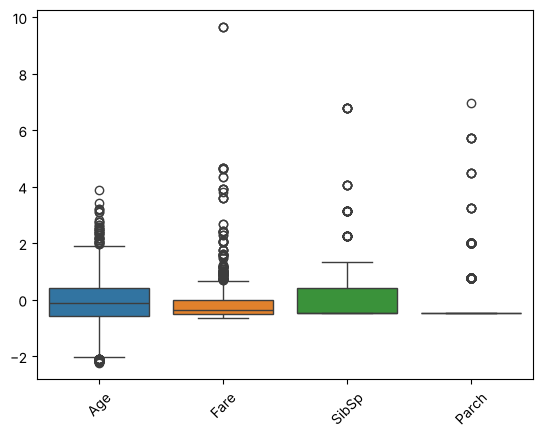

In [5]:
sns.boxplot(data=std)
plt.xticks(rotation=45)
plt.show()

## 5. IQR table

In [6]:
rows = []
for col in num:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, q1, q3, iqr, low, high, count])

table = pd.DataFrame(rows, columns=[
    "Column", "Q1", "Q3", "IQR", "Lower", "Upper", "Outliers"
])
print(table)

  Column       Q1    Q3      IQR   Lower    Upper  Outliers
0    Age  22.0000  35.0  13.0000   2.500  54.5000        66
1   Fare   7.9104  31.0  23.0896 -26.724  65.6344       116
2  SibSp   0.0000   1.0   1.0000  -1.500   2.5000        46
3  Parch   0.0000   0.0   0.0000   0.000   0.0000       213


## 6. Remove outliers from `Fare` and save

In [7]:
low = table.set_index("Column").loc["Fare", "Lower"]
high = table.set_index("Column").loc["Fare", "Upper"]

clean = df[df["Fare"].between(low, high)]
print("Before:", len(df), "After:", len(clean))

clean.to_csv("clean.csv", index=False)
print("Saved clean.csv")

Before: 891 After: 775
Saved clean.csv


## Result / Conclusion
- 177 missing `Age` values were filled with the median (28) and 2 missing `Embarked` values with the mode (S); `Cabin` (77% missing) is not used.
- `Sex` and `Embarked` were one-hot encoded; `Sex` was also label encoded (female = 0, male = 1).
- IQR outliers: Age 66, Fare 116, SibSp 46, Parch 213 (Parch has IQR = 0, so every non-zero value counts as an outlier).
- Removing the 116 `Fare` outliers keeps 775 of 891 rows, saved as `clean.csv`.